# RQ13 — PU generalization across redundancy and homology constraints

## Scientific question

**How do progressively stricter redundancy reduction (`R`) and homology separation (`S`) reshape positive recovery in positive–unlabeled learning, and do dedicated PU methods gain or lose advantage relative to naive P-vs-U as generalization becomes more stringent?**

RQ13 extends the PU paradigm analysis from RQ12 into the complete factorial `R × S` landscape.

The central questions are:

1. How strongly does positive recovery change as `R` becomes stricter?
2. How strongly does recovery change as `S` becomes stricter?
3. Are `R` and `S` effects additive or strongly context-dependent?
4. Is PU recovery primarily redundancy-sensitive or homology-sensitive?
5. Do BaggingPU or Elkan–Noto gain more relative to naive P-vs-U under stricter `R` or `S` conditions?
6. Are method gains stable across the generalization landscape, or are they regime-specific?

## Primary PU diagnostics

RQ13 does **not** treat U as confirmed negative.

Primary metric:

\[
\mathrm{Recovery}_{U95}
=
\Pr(s_P \ge Q_{0.95}(s_U))
\]

Supporting metrics:

- median percentile position of labeled positives relative to U;
- recovery above U90;
- recovery above U99;
- **strict** U99 recovery (`P > U99`) as a tie-resolution diagnostic.

U95 is the main response variable because it is stringent enough to characterize upper-tail recovery while being substantially less vulnerable than U99 to the Elkan–Noto ceiling plateau identified in RQ12.

U99 is retained only with explicit tie diagnostics.

## R/S interpretation contract

Lower `R` and lower `S` are more stringent.

For a metric \(M\):

\[
\Delta_R(S)=M(R30,S)-M(R90,S)
\]

and

\[
\Delta_S(R)=M(R,S30)-M(R,S90).
\]

Negative values indicate lower positive recovery under the stricter condition.

However, native R/S test sets are not automatically entity-level paired. Therefore:

- `R` and `S` deltas are **native-test generalization contrasts**;
- they are not causal paired-sequence effects;
- method-vs-naive gains **within the same R/S cell are paired**, because all methods score the same frozen native test entities;
- differences in method gain across R/S remain native-test contrasts across cells.

Thresholds are treated as ordered categorical conditions, not as a linear numerical scale.

## Scope boundary

RQ13 focuses only on **R/S geometry and dedicated-PU gains**.

Deferred:

- conservative vs broad U-universe effect → **RQ14**;
- representation × PU-method interaction → **RQ15**;
- common-test R/S decomposition → **RQ16**;
- bootstrap uncertainty → **RQ17**;
- runtime / compute → **RQ18**.

The two PU tasks are shown separately for consistency, but RQ13 does not interpret their difference as the U-universe effect.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 400)
pd.set_option("display.width", 240)
pd.set_option("display.max_rows", 400)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

TASKS = ["pu_conservative", "pu_broad"]
METHODS = ["naive", "baggingpu", "elkan_noto"]
DEDICATED_METHODS = ["baggingpu", "elkan_noto"]

METHOD_LABELS = {
    "naive": "Naive P-vs-U",
    "baggingpu": "BaggingPU",
    "elkan_noto": "Elkan–Noto",
}

PRIMARY = "fraction_P_above_U95"
SECONDARY = [
    "median_P_percentile_vs_U",
    "fraction_P_above_U90",
    "fraction_P_above_U99",
    "fraction_P_strictly_above_U99",
]

ANALYSIS_METRICS = [PRIMARY] + SECONDARY

PRACTICAL_TIE = {
    "fraction_P_above_U95": 0.02,
    "fraction_P_above_U90": 0.02,
    "fraction_P_above_U99": 0.02,
    "fraction_P_strictly_above_U99": 0.02,
    "median_P_percentile_vs_U": 0.02,
}

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_pu/stage12b2").is_dir()
            and (candidate / "results/analysis_pu/stage12a_qc").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate project root containing Stage12B2 and PU QC outputs."
    )

ROOT = find_project_root()
PU_DIR = ROOT / "results/analysis_pu/stage12b2"
PU_QC = ROOT / "results/analysis_pu/stage12a_qc"
CACHE_DIR = ROOT / "results/analysis_pu/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("PU_DIR:", PU_DIR)

ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
PU_DIR: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/stage12b2


# 1. Validate the frozen PU benchmark

In [2]:
manifest_path = PU_DIR / "stage12b2_manifest.json"
if not manifest_path.is_file():
    raise FileNotFoundError(manifest_path)

manifest = json.loads(manifest_path.read_text())

if manifest.get("status") != "PASS":
    raise RuntimeError(
        f"Stage12B2 status is {manifest.get('status')}; RQ13 requires PASS."
    )

master = pd.read_csv(
    PU_DIR / "pu_master_results.tsv",
    sep="\t",
    low_memory=False,
)

registry = pd.read_csv(
    PU_QC / "pu_completed_registry.tsv",
    sep="\t",
    low_memory=False,
)

print("PU families:", len(master))
print("Registry rows:", len(registry))

assert len(master) == 768
assert len(registry) == 768

coverage = (
    master.groupby(
        ["task", "R", "S", "representation", "method", "algorithm"]
    )
    .size()
)

assert coverage.eq(1).all()
assert len(coverage) == 768

display(
    master.groupby(["task", "method"]).size().unstack()
)

PU families: 768
Registry rows: 768


method,baggingpu,elkan_noto,naive
task,,,
pu_broad,128,128,128
pu_conservative,128,128,128


# 2. Load RQ12 canonical score diagnostics, with a reconstruction fallback

In [3]:
RQ12_NATIVE = CACHE_DIR / "rq12_pu_native_score_diagnostics.tsv"

def detect_score_col(df):
    for c in ["score_positive", "score", "corrected_score", "probability"]:
        if c in df.columns:
            return c
    raise KeyError(
        f"No score column found; columns={list(df.columns)}"
    )

def percentile_against_u(values, u_sorted):
    values = np.asarray(values, dtype=float)
    u_sorted = np.asarray(u_sorted, dtype=float)
    if len(u_sorted) == 0:
        return np.full(len(values), np.nan)
    return np.searchsorted(
        u_sorted,
        values,
        side="right",
    ) / len(u_sorted)

def tie_fraction(values, threshold):
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return np.nan
    return float(
        np.mean(
            np.isclose(
                values,
                threshold,
                rtol=0.0,
                atol=1e-12,
            )
        )
    )

def rebuild_native_from_scores():
    rows = []

    for rec in registry.itertuples(index=False):
        score_path = Path(rec.path) / "outer_test_scores.parquet"
        if not score_path.is_file():
            raise FileNotFoundError(score_path)

        df = pd.read_parquet(score_path)

        if "observed_role" not in df.columns:
            raise KeyError(f"{score_path}: missing observed_role")

        score_col = detect_score_col(df)
        roles = df["observed_role"].astype(str).str.upper()
        scores = pd.to_numeric(df[score_col], errors="coerce")

        p = scores[roles.eq("P")].dropna().to_numpy(dtype=float)
        u = scores[roles.eq("U")].dropna().to_numpy(dtype=float)

        if len(p) == 0 or len(u) == 0:
            raise RuntimeError(
                f"{score_path}: nP={len(p)}, nU={len(u)}"
            )

        u_sorted = np.sort(u)
        q90, q95, q99 = np.quantile(u, [0.90, 0.95, 0.99])
        p_percentiles = percentile_against_u(p, u_sorted)

        row = {
            "experiment_id": rec.experiment_id,
            "task": rec.task,
            "R": int(rec.R),
            "S": int(rec.S),
            "representation": rec.representation,
            "method": rec.method,
            "algorithm": rec.algorithm,
            "n_P_test": len(p),
            "n_U_test": len(u),
            "median_P_percentile_vs_U": float(np.median(p_percentiles)),
            "fraction_P_above_U90": float(np.mean(p >= q90)),
            "fraction_P_above_U95": float(np.mean(p >= q95)),
            "fraction_P_above_U99": float(np.mean(p >= q99)),
            "fraction_P_strictly_above_U99": float(np.mean(p > q99)),
            "U_q99": float(q99),
            "U_tie_fraction_at_q99": tie_fraction(u, q99),
            "U_fraction_at_score_1": float(
                np.mean(np.isclose(u, 1.0, rtol=0.0, atol=1e-12))
            ),
            "P_fraction_at_score_1": float(
                np.mean(np.isclose(p, 1.0, rtol=0.0, atol=1e-12))
            ),
        }

        row["P_recovery_tie_component_U99"] = (
            row["fraction_P_above_U99"]
            - row["fraction_P_strictly_above_U99"]
        )

        rows.append(row)

    return pd.DataFrame(rows)

if RQ12_NATIVE.is_file():
    native = pd.read_csv(
        RQ12_NATIVE,
        sep="\t",
        low_memory=False,
    )
    source = "RQ12 cache"
else:
    native = rebuild_native_from_scores()
    source = "reconstructed from frozen outer-test scores"

print("Native diagnostic source:", source)
print("Rows:", len(native))

assert len(native) == 768

required_native = {
    "experiment_id",
    "task",
    "R",
    "S",
    "representation",
    "method",
    "algorithm",
    "n_P_test",
    "n_U_test",
    *ANALYSIS_METRICS,
}

missing = required_native - set(native.columns)
if missing:
    raise KeyError(
        f"Native PU diagnostics missing columns: {sorted(missing)}"
    )

display(native.head())

Native diagnostic source: RQ12 cache
Rows: 768


,experiment_id,task,R,S,representation,method,algorithm,n_P_test,n_U_test,median_P_score,median_U_score,median_score_gap_P_minus_U,mean_P_percentile_vs_U,median_P_percentile_vs_U,fraction_P_above_U90,fraction_P_above_U95,fraction_P_above_U99,fraction_P_strictly_above_U90,fraction_P_strictly_above_U95,fraction_P_strictly_above_U99,fraction_U_score_ge_050,fraction_P_score_ge_050,U_q90,U_q95,U_q99,U_tie_fraction_at_q90,U_tie_fraction_at_q95,U_tie_fraction_at_q99,P_tie_fraction_at_Uq90,P_tie_fraction_at_Uq95,P_tie_fraction_at_Uq99,U_fraction_at_score_1,P_fraction_at_score_1,P_recovery_tie_component_U90,P_recovery_tie_component_U95,P_recovery_tie_component_U99
0,PU__pu_broad__R90__S90__roxy_48__naive__LR,pu_broad,90,90,roxy_48,naive,LR,1428,64386,0.842071,0.125035,0.717037,0.913919,0.969279,0.759804,0.606443,0.263305,0.759804,0.606443,0.263305,0.182928,0.867647,0.664297,0.787535,0.916668,0.0,0.00000,0.00000,0.0,0.000000,0.000000,0.00000,0.000000,0.0,0.000000,0.000000
1,PU__pu_broad__R90__S90__roxy_48__naive__XGB,pu_broad,90,90,roxy_48,naive,XGB,1428,64386,0.896035,0.003444,0.892591,0.952163,0.993935,0.887955,0.814426,0.585434,0.887955,0.814426,0.585434,0.035256,0.768908,0.152671,0.366174,0.833592,0.0,0.00000,0.00000,0.0,0.000000,0.000000,0.00000,0.000000,0.0,0.000000,0.000000
2,PU__pu_broad__R90__S90__roxy_48__baggingpu__LR,pu_broad,90,90,roxy_48,baggingpu,LR,1428,64386,0.843071,0.127132,0.715939,0.914066,0.969512,0.757703,0.607843,0.264006,0.757703,0.607843,0.264006,0.184419,0.866947,0.666161,0.788119,0.916082,0.0,0.00000,0.00000,0.0,0.000000,0.000000,0.00000,0.000000,0.0,0.000000,0.000000
3,PU__pu_broad__R90__S90__roxy_48__baggingpu__XGB,pu_broad,90,90,roxy_48,baggingpu,XGB,1428,64386,0.974142,0.024552,0.949590,0.952396,0.993089,0.876050,0.799720,0.567927,0.876050,0.799720,0.567927,0.108564,0.881653,0.534183,0.771410,0.961027,0.0,0.00000,0.00000,0.0,0.000000,0.000000,0.00000,0.000000,0.0,0.000000,0.000000
4,PU__pu_broad__R90__S90__roxy_48__elkan_noto__LR,pu_broad,90,90,roxy_48,elkan_noto,LR,1428,64386,1.000000,0.163790,0.836210,0.925649,1.000000,0.759804,0.642157,0.642157,0.759804,0.000000,0.000000,0.256593,0.912465,0.870198,1.000000,1.000000,0.0,0.05919,0.05919,0.0,0.642157,0.642157,0.05919,0.642157,0.0,0.642157,0.642157


This keeps RQ13 consistent with the corrected RQ12 semantics:

- inclusive `>=` for canonical U90/U95/U99 recovery;
- strict `>` only as a tie-resolution diagnostic;
- U remains unlabeled throughout.

# 3. QC: native test support must be invariant across methods/representations/learners within each R/S cell

In [4]:
support_qc = (
    native.groupby(["task", "R", "S"])
    .agg(
        n_P_min=("n_P_test", "min"),
        n_P_max=("n_P_test", "max"),
        n_U_min=("n_U_test", "min"),
        n_U_max=("n_U_test", "max"),
        n_models=("experiment_id", "size"),
    )
    .reset_index()
)

support_qc["P_support_consistent"] = (
    support_qc["n_P_min"] == support_qc["n_P_max"]
)
support_qc["U_support_consistent"] = (
    support_qc["n_U_min"] == support_qc["n_U_max"]
)

display(
    support_qc[
        ["P_support_consistent", "U_support_consistent", "n_models"]
    ].value_counts()
)

assert support_qc["P_support_consistent"].all()
assert support_qc["U_support_consistent"].all()
assert support_qc["n_models"].eq(24).all()

P_support_consistent  U_support_consistent  n_models
True                  True                  24          32
Name: count, dtype: int64

# 4. Cell-level recovery landscape

In [5]:
cell_summary = (
    native.groupby(
        ["task", "method", "R", "S"]
    )
    .agg(
        n_models=("experiment_id", "size"),
        U95_median=("fraction_P_above_U95", "median"),
        U95_mean=("fraction_P_above_U95", "mean"),
        U95_q25=("fraction_P_above_U95", lambda x: x.quantile(0.25)),
        U95_q75=("fraction_P_above_U95", lambda x: x.quantile(0.75)),
        P_percentile_median=("median_P_percentile_vs_U", "median"),
        U90_median=("fraction_P_above_U90", "median"),
        U99_median=("fraction_P_above_U99", "median"),
        strict_U99_median=("fraction_P_strictly_above_U99", "median"),
        n_P_test=("n_P_test", "first"),
        n_U_test=("n_U_test", "first"),
    )
    .reset_index()
)

assert cell_summary["n_models"].eq(8).all()

display(cell_summary.head(12))

,task,method,R,S,n_models,U95_median,U95_mean,U95_q25,U95_q75,P_percentile_median,U90_median,U99_median,strict_U99_median,n_P_test,n_U_test
0,pu_broad,baggingpu,30,30,8,0.727088,0.684318,0.560081,0.800916,0.985830,0.808554,0.455193,0.455193,491,34368
1,pu_broad,baggingpu,30,50,8,0.755647,0.711242,0.588809,0.816222,0.989157,0.834702,0.506160,0.506160,487,34399
2,pu_broad,baggingpu,30,70,8,0.728216,0.695539,0.581950,0.814834,0.988826,0.817427,0.491701,0.491701,482,34389
3,pu_broad,baggingpu,30,90,8,0.718941,0.686354,0.560591,0.806008,0.987631,0.792261,0.481670,0.481670,491,34361
4,pu_broad,baggingpu,50,30,8,0.751453,0.708576,0.568314,0.842297,0.989259,0.827035,0.499273,0.499273,688,41917
5,pu_broad,baggingpu,50,50,8,0.762943,0.713386,0.580041,0.850136,0.990401,0.843324,0.525204,0.525204,734,41878
6,pu_broad,baggingpu,50,70,8,0.786212,0.731894,0.589485,0.864554,0.991194,0.852368,0.528552,0.528552,718,41876
7,pu_broad,baggingpu,50,90,8,0.740661,0.697917,0.553879,0.843750,0.988652,0.839080,0.483477,0.483477,696,41945
8,pu_broad,baggingpu,70,30,8,0.772354,0.719092,0.570027,0.870666,0.990684,0.861314,0.519161,0.519161,1096,50717
9,pu_broad,baggingpu,70,50,8,0.802889,0.729147,0.554986,0.884902,0.992198,0.866729,0.564306,0.564306,1073,50822


# 5. U95 recovery matrices by PU method and task

In [6]:
for task in TASKS:
    print("\nTASK:", task)

    for method in METHODS:
        matrix = (
            cell_summary[
                cell_summary["task"].eq(task)
                & cell_summary["method"].eq(method)
            ]
            .pivot(
                index="R",
                columns="S",
                values="U95_median",
            )
            .reindex(
                index=R_LEVELS,
                columns=S_LEVELS,
            )
        )

        print("\n", METHOD_LABELS[method])
        display(matrix)


TASK: pu_conservative

 Naive P-vs-U


S,90,70,50,30
R,,,,
90,0.889437,0.876582,0.863292,0.850204
70,0.859060,0.836390,0.837113,0.831074
50,0.802557,0.814505,0.827778,0.787518
30,0.769628,0.802301,0.776371,0.771186



 BaggingPU


S,90,70,50,30
R,,,,
90,0.886620,0.873418,0.860882,0.845448
70,0.853308,0.837355,0.839175,0.827424
50,0.797585,0.808229,0.835417,0.789621
30,0.780992,0.808577,0.782700,0.773305



 Elkan–Noto


S,90,70,50,30
R,,,,
90,0.889437,0.876582,0.863292,0.850204
70,0.859060,0.836390,0.837113,0.831074
50,0.802557,0.814505,0.827778,0.787518
30,0.769628,0.802301,0.776371,0.771186


... (2 outputs left out)


 BaggingPU


S,90,70,50,30
R,,,,
90,0.832283,0.831246,0.826531,0.814815
70,0.800554,0.783256,0.802889,0.772354
50,0.740661,0.786212,0.762943,0.751453
30,0.718941,0.728216,0.755647,0.727088



 Elkan–Noto


S,90,70,50,30
R,,,,
90,0.839986,0.836813,0.827518,0.812121
70,0.807018,0.786047,0.802889,0.764599
50,0.741379,0.779944,0.762262,0.747093
30,0.705703,0.713693,0.745380,0.702648


# 6. Global R trajectory

,method,R,mean,median,q25,q75
0,baggingpu,30,0.732441,0.762729,0.616870,0.852784
1,baggingpu,50,0.741819,0.791427,0.599193,0.873814
2,baggingpu,70,0.763502,0.823838,0.621586,0.898145
3,baggingpu,90,0.793473,0.861343,0.646976,0.922884
4,elkan_noto,30,0.702927,0.748208,0.625059,0.848733
5,elkan_noto,50,0.725711,0.793678,0.639441,0.882959
6,elkan_noto,70,0.753456,0.820897,0.645444,0.905738
7,elkan_noto,90,0.784575,0.860676,0.657798,0.931550
8,naive,30,0.697669,0.748208,0.602524,0.848733
9,naive,50,0.717099,0.793678,0.598348,0.882959


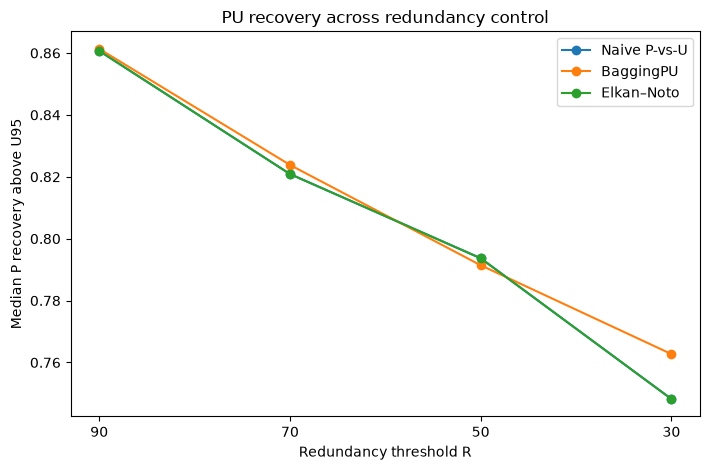

In [7]:
R_curve = (
    native.groupby(["method", "R"])
    [PRIMARY]
    .agg(
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)

display(R_curve)

fig, ax = plt.subplots(figsize=(7.2, 4.8))

for method in METHODS:
    g = (
        R_curve[
            R_curve["method"].eq(method)
        ]
        .assign(
            order=lambda x: x["R"].map(
                {90: 0, 70: 1, 50: 2, 30: 3}
            )
        )
        .sort_values("order")
    )

    ax.plot(
        g["R"].astype(str),
        g["median"],
        marker="o",
        label=METHOD_LABELS[method],
    )

ax.set_xlabel("Redundancy threshold R")
ax.set_ylabel("Median P recovery above U95")
ax.set_title("PU recovery across redundancy control")
ax.legend()
plt.tight_layout()
plt.show()

# 7. Global S trajectory

,method,S,mean,median,q25,q75
0,baggingpu,30,0.748118,0.784205,0.607193,0.882670
1,baggingpu,50,0.760414,0.805871,0.629052,0.889628
2,baggingpu,70,0.762063,0.807124,0.641792,0.894313
3,baggingpu,90,0.760641,0.790899,0.612188,0.895917
4,elkan_noto,30,0.732439,0.794462,0.633725,0.881822
5,elkan_noto,50,0.743741,0.807375,0.643442,0.890035
6,elkan_noto,70,0.744886,0.810935,0.656070,0.897234
7,elkan_noto,90,0.745602,0.812508,0.645918,0.894766
8,naive,30,0.723760,0.794462,0.603072,0.881822
9,naive,50,0.735444,0.807375,0.615800,0.890035


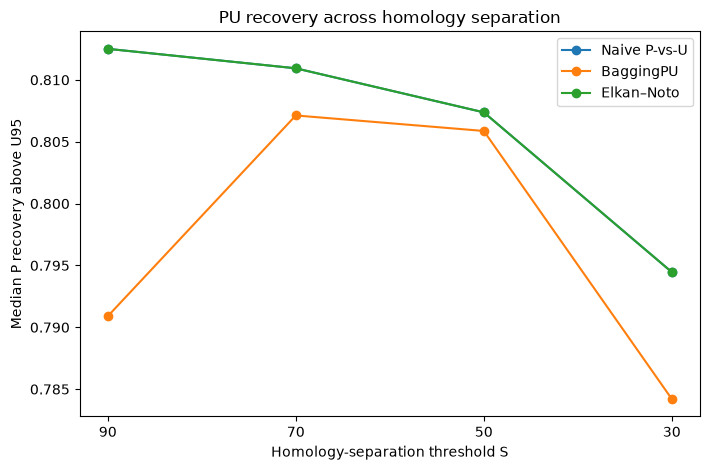

In [8]:
S_curve = (
    native.groupby(["method", "S"])
    [PRIMARY]
    .agg(
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)

display(S_curve)

fig, ax = plt.subplots(figsize=(7.2, 4.8))

for method in METHODS:
    g = (
        S_curve[
            S_curve["method"].eq(method)
        ]
        .assign(
            order=lambda x: x["S"].map(
                {90: 0, 70: 1, 50: 2, 30: 3}
            )
        )
        .sort_values("order")
    )

    ax.plot(
        g["S"].astype(str),
        g["median"],
        marker="o",
        label=METHOD_LABELS[method],
    )

ax.set_xlabel("Homology-separation threshold S")
ax.set_ylabel("Median P recovery above U95")
ax.set_title("PU recovery across homology separation")
ax.legend()
plt.tight_layout()
plt.show()

These global curves are descriptive summaries across both PU universes, representations, and base learners.

The per-surface contrasts below are the main evidence because they preserve the full factorial grouping.

# 8. Build complete model-level R/S surfaces

In [9]:
SURFACE_KEYS = [
    "task",
    "representation",
    "method",
    "algorithm",
]

surface_counts = (
    native.groupby(SURFACE_KEYS)
    .size()
    .rename("n_cells")
    .reset_index()
)

display(surface_counts["n_cells"].value_counts().sort_index())
assert surface_counts["n_cells"].eq(16).all()
assert len(surface_counts) == 48

print("Complete PU R/S surfaces:", len(surface_counts))

n_cells
16    48
Name: count, dtype: int64

Complete PU R/S surfaces: 48


In [10]:
def surface_lookup(group, metric):
    return {
        (int(r), int(s)): float(v)
        for r, s, v in zip(
            group["R"],
            group["S"],
            group[metric],
        )
        if pd.notna(v)
    }

def extreme_r_effects(df, metric):
    rows = []
    for keys, grp in df.groupby(SURFACE_KEYS):
        lookup = surface_lookup(grp, metric)
        for s in S_LEVELS:
            if (90, s) in lookup and (30, s) in lookup:
                row = dict(zip(SURFACE_KEYS, keys))
                row.update({
                    "metric": metric,
                    "S_fixed": s,
                    "value_R90": lookup[(90, s)],
                    "value_R30": lookup[(30, s)],
                    "delta_R30_minus_R90": (
                        lookup[(30, s)] - lookup[(90, s)]
                    ),
                })
                rows.append(row)
    return pd.DataFrame(rows)

def extreme_s_effects(df, metric):
    rows = []
    for keys, grp in df.groupby(SURFACE_KEYS):
        lookup = surface_lookup(grp, metric)
        for r in R_LEVELS:
            if (r, 90) in lookup and (r, 30) in lookup:
                row = dict(zip(SURFACE_KEYS, keys))
                row.update({
                    "metric": metric,
                    "R_fixed": r,
                    "value_S90": lookup[(r, 90)],
                    "value_S30": lookup[(r, 30)],
                    "delta_S30_minus_S90": (
                        lookup[(r, 30)] - lookup[(r, 90)]
                    ),
                })
                rows.append(row)
    return pd.DataFrame(rows)

R_effects = pd.concat(
    [
        extreme_r_effects(native, metric)
        for metric in ANALYSIS_METRICS
    ],
    ignore_index=True,
)

S_effects = pd.concat(
    [
        extreme_s_effects(native, metric)
        for metric in ANALYSIS_METRICS
    ],
    ignore_index=True,
)

print("R extreme contrasts:", len(R_effects))
print("S extreme contrasts:", len(S_effects))

R extreme contrasts: 960
S extreme contrasts: 960


# 9. Overall R90→R30 effect on U95 recovery

In [11]:
primary_R = R_effects[
    R_effects["metric"].eq(PRIMARY)
]

R_overall = (
    primary_R["delta_R30_minus_R90"]
    .agg(
        [
            "count",
            "mean",
            "median",
            "min",
            "max",
        ]
    )
    .to_frame("value")
)

display(R_overall)

print(
    "Fraction negative:",
    (primary_R["delta_R30_minus_R90"] < 0).mean(),
)
print(
    "Median absolute effect:",
    primary_R["delta_R30_minus_R90"].abs().median(),
)

,value
count,192.000000
mean,-0.074330
median,-0.073333
min,-0.210590
max,0.037425


Fraction negative: 0.9635416666666666
Median absolute effect: 0.07333251331594509


# 10. R effect by method and PU task

In [12]:
R_by_method_task = (
    primary_R.groupby(["task", "method"])
    ["delta_R30_minus_R90"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_negative=lambda x: (x < 0).mean(),
        fraction_abs_le_002=lambda x: (x.abs() <= 0.02).mean(),
    )
    .reset_index()
)

display(R_by_method_task)

,task,method,n,mean,median,median_abs,fraction_negative,fraction_abs_le_002
0,pu_broad,baggingpu,32,-0.069445,-0.072131,0.072131,0.93750,0.09375
1,pu_broad,elkan_noto,32,-0.089755,-0.084795,0.084795,0.96875,0.09375
2,pu_broad,naive,32,-0.087084,-0.084348,0.084348,0.96875,0.03125
3,pu_conservative,baggingpu,32,-0.052618,-0.051175,0.051175,0.90625,0.21875
4,pu_conservative,elkan_noto,32,-0.073540,-0.070814,0.070814,1.00000,0.09375
5,pu_conservative,naive,32,-0.073540,-0.070814,0.070814,1.00000,0.09375


# 11. Overall S90→S30 effect on U95 recovery

In [13]:
primary_S = S_effects[
    S_effects["metric"].eq(PRIMARY)
]

S_overall = (
    primary_S["delta_S30_minus_S90"]
    .agg(
        [
            "count",
            "mean",
            "median",
            "min",
            "max",
        ]
    )
    .to_frame("value")
)

display(S_overall)

print(
    "Fraction negative:",
    (primary_S["delta_S30_minus_S90"] < 0).mean(),
)
print(
    "Median absolute effect:",
    primary_S["delta_S30_minus_S90"].abs().median(),
)

,value
count,192.000000
mean,-0.013889
median,-0.007859
min,-0.119237
max,0.056853


Fraction negative: 0.7239583333333334
Median absolute effect: 0.012191241328135205


# 12. S effect by method and PU task

In [14]:
S_by_method_task = (
    primary_S.groupby(["task", "method"])
    ["delta_S30_minus_S90"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_negative=lambda x: (x < 0).mean(),
        fraction_abs_le_002=lambda x: (x.abs() <= 0.02).mean(),
    )
    .reset_index()
)

display(S_by_method_task)

,task,method,n,mean,median,median_abs,fraction_negative,fraction_abs_le_002
0,pu_broad,baggingpu,32,-0.009554,-0.004611,0.011322,0.62500,0.68750
1,pu_broad,elkan_noto,32,-0.007412,-0.004248,0.011698,0.65625,0.71875
2,pu_broad,naive,32,-0.013043,-0.004248,0.015646,0.65625,0.65625
3,pu_conservative,baggingpu,32,-0.015493,-0.009200,0.011760,0.78125,0.71875
4,pu_conservative,elkan_noto,32,-0.018914,-0.010823,0.012799,0.81250,0.65625
5,pu_conservative,naive,32,-0.018914,-0.010823,0.012799,0.81250,0.65625


# 13. R and S effects across supporting PU metrics

In [15]:
metric_effect_summary = []

for metric in ANALYSIS_METRICS:
    rg = R_effects[
        R_effects["metric"].eq(metric)
    ]["delta_R30_minus_R90"]

    sg = S_effects[
        S_effects["metric"].eq(metric)
    ]["delta_S30_minus_S90"]

    metric_effect_summary.append({
        "metric": metric,
        "R_median": rg.median(),
        "R_median_abs": rg.abs().median(),
        "R_fraction_negative": (rg < 0).mean(),
        "S_median": sg.median(),
        "S_median_abs": sg.abs().median(),
        "S_fraction_negative": (sg < 0).mean(),
    })

metric_effect_summary = pd.DataFrame(
    metric_effect_summary
)

display(metric_effect_summary)

,metric,R_median,R_median_abs,R_fraction_negative,S_median,S_median_abs,S_fraction_negative
0,fraction_P_above_U95,-0.073333,0.073333,0.963542,-0.007859,0.012191,0.723958
1,median_P_percentile_vs_U,-0.001608,0.001871,0.666667,-0.000063,0.000392,0.520833
2,fraction_P_above_U90,-0.058430,0.058430,1.000000,-0.008672,0.011127,0.755208
3,fraction_P_above_U99,-0.092468,0.092468,0.916667,-0.010925,0.019530,0.661458
4,fraction_P_strictly_above_U99,-0.086702,0.086702,0.723958,-0.002374,0.013002,0.531250


Consistency across U90, U95, positive-percentile position, and strict U99 strengthens a generalization conclusion.

Canonical U99 is interpreted together with the tie audit because Elkan–Noto can accumulate probability mass at score 1.0.

# 14. Stepwise R effects

In [16]:
R_STEPS = [(90, 70), (70, 50), (50, 30)]

step_R_rows = []

for keys, grp in native.groupby(SURFACE_KEYS):
    lookup = surface_lookup(grp, PRIMARY)

    for s in S_LEVELS:
        for r_from, r_to in R_STEPS:
            if (
                (r_from, s) in lookup
                and (r_to, s) in lookup
            ):
                row = dict(zip(SURFACE_KEYS, keys))
                row.update({
                    "S_fixed": s,
                    "R_from": r_from,
                    "R_to": r_to,
                    "step": f"R{r_from}->R{r_to}",
                    "delta": (
                        lookup[(r_to, s)]
                        - lookup[(r_from, s)]
                    ),
                })
                step_R_rows.append(row)

step_R = pd.DataFrame(step_R_rows)

step_R_summary = (
    step_R.groupby("step")["delta"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_negative=lambda x: (x < 0).mean(),
    )
    .reindex(
        [f"R{a}->R{b}" for a, b in R_STEPS]
    )
)

display(step_R_summary)

,n,mean,median,median_abs,fraction_negative
step,,,,,
R90->R70,192,-0.031338,-0.025493,0.025493,0.921875
R70->R50,192,-0.025795,-0.028280,0.030531,0.864583
R50->R30,192,-0.017197,-0.018112,0.024440,0.765625


# 15. Stepwise S effects

In [17]:
S_STEPS = [(90, 70), (70, 50), (50, 30)]

step_S_rows = []

for keys, grp in native.groupby(SURFACE_KEYS):
    lookup = surface_lookup(grp, PRIMARY)

    for r in R_LEVELS:
        for s_from, s_to in S_STEPS:
            if (
                (r, s_from) in lookup
                and (r, s_to) in lookup
            ):
                row = dict(zip(SURFACE_KEYS, keys))
                row.update({
                    "R_fixed": r,
                    "S_from": s_from,
                    "S_to": s_to,
                    "step": f"S{s_from}->S{s_to}",
                    "delta": (
                        lookup[(r, s_to)]
                        - lookup[(r, s_from)]
                    ),
                })
                step_S_rows.append(row)

step_S = pd.DataFrame(step_S_rows)

step_S_summary = (
    step_S.groupby("step")["delta"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_negative=lambda x: (x < 0).mean(),
    )
    .reindex(
        [f"S{a}->S{b}" for a, b in S_STEPS]
    )
)

display(step_S_summary)

,n,mean,median,median_abs,fraction_negative
step,,,,,
S90->S70,192,-0.000057,0.001470,0.015539,0.494792
S70->S50,192,-0.002071,-0.003032,0.012506,0.578125
S50->S30,192,-0.011761,-0.009313,0.015147,0.770833


# 16. Shape classification of R and S trajectories

In [18]:
def classify_curve(values, tol=1e-12):
    values = np.asarray(values, dtype=float)
    diffs = np.diff(values)

    if np.all(np.abs(diffs) <= tol):
        return "flat"
    if np.all(diffs <= tol) and np.any(diffs < -tol):
        return "monotonic_decrease"
    if np.all(diffs >= -tol) and np.any(diffs > tol):
        return "monotonic_increase"
    return "nonmonotonic"

r_shape_rows = []

for keys, grp in native.groupby(SURFACE_KEYS):
    lookup = surface_lookup(grp, PRIMARY)

    for s in S_LEVELS:
        vals = [
            lookup[(r, s)]
            for r in R_LEVELS
        ]
        row = dict(zip(SURFACE_KEYS, keys))
        row.update({
            "S_fixed": s,
            "shape": classify_curve(vals),
            "range": max(vals) - min(vals),
        })
        r_shape_rows.append(row)

s_shape_rows = []

for keys, grp in native.groupby(SURFACE_KEYS):
    lookup = surface_lookup(grp, PRIMARY)

    for r in R_LEVELS:
        vals = [
            lookup[(r, s)]
            for s in S_LEVELS
        ]
        row = dict(zip(SURFACE_KEYS, keys))
        row.update({
            "R_fixed": r,
            "shape": classify_curve(vals),
            "range": max(vals) - min(vals),
        })
        s_shape_rows.append(row)

R_shapes = pd.DataFrame(r_shape_rows)
S_shapes = pd.DataFrame(s_shape_rows)

print("R-trajectory shapes")
display(
    R_shapes["shape"]
    .value_counts(normalize=True)
    .rename("fraction")
    .to_frame()
)

print("S-trajectory shapes")
display(
    S_shapes["shape"]
    .value_counts(normalize=True)
    .rename("fraction")
    .to_frame()
)

R-trajectory shapes


,fraction
shape,
monotonic_decrease,0.625000
nonmonotonic,0.364583
monotonic_increase,0.010417


S-trajectory shapes


,fraction
shape,
nonmonotonic,0.8125
monotonic_decrease,0.1875


A high nonmonotonic fraction means there is no single threshold breakpoint that generalizes across model/task regimes.

Shape classification is descriptive and does not imply that identity thresholds form a linear scale.

# 17. Extreme R×S interaction

In [19]:
interaction_rows = []

for keys, grp in native.groupby(SURFACE_KEYS):
    lookup = surface_lookup(grp, PRIMARY)

    required = [
        (90, 90),
        (30, 90),
        (90, 30),
        (30, 30),
    ]

    if not all(cell in lookup for cell in required):
        continue

    m00 = lookup[(90, 90)]
    m10 = lookup[(30, 90)]
    m01 = lookup[(90, 30)]
    m11 = lookup[(30, 30)]

    interaction = (
        (m11 - m01)
        - (m10 - m00)
    )

    row = dict(zip(SURFACE_KEYS, keys))
    row.update({
        "M_R90_S90": m00,
        "M_R30_S90": m10,
        "M_R90_S30": m01,
        "M_R30_S30": m11,
        "delta_R_at_S90": m10 - m00,
        "delta_R_at_S30": m11 - m01,
        "delta_S_at_R90": m01 - m00,
        "delta_S_at_R30": m11 - m10,
        "interaction": interaction,
    })

    interaction_rows.append(row)

interactions = pd.DataFrame(
    interaction_rows
)

display(
    interactions["interaction"]
    .agg(["count", "mean", "median", "min", "max"])
    .to_frame("value")
)

print(
    "Median |interaction|:",
    interactions["interaction"].abs().median(),
)
print(
    "Fraction interaction > 0:",
    (interactions["interaction"] > 0).mean(),
)

,value
count,48.000000
mean,0.040508
median,0.026624
min,-0.013768
max,0.139714


Median |interaction|: 0.026624252593951236
Fraction interaction > 0: 0.8958333333333334


The interaction sign is not automatically labeled “substitution” or “synergy” because PU recovery can increase or decrease across native R/S cells.

The robust quantity here is **non-additivity magnitude**, `|interaction|`.

# 18. R versus S dominance in PU recovery

In [20]:
dominance_rows = []

for keys, grp in native.groupby(SURFACE_KEYS):
    lookup = surface_lookup(grp, PRIMARY)

    r_effects = [
        abs(lookup[(30, s)] - lookup[(90, s)])
        for s in S_LEVELS
    ]
    s_effects = [
        abs(lookup[(r, 30)] - lookup[(r, 90)])
        for r in R_LEVELS
    ]

    E_R = float(np.median(r_effects))
    E_S = float(np.median(s_effects))
    denom = E_R + E_S

    D = (
        (E_R - E_S) / denom
        if denom > 0
        else np.nan
    )

    if np.isnan(D):
        classification = "undefined"
    elif D > 0.20:
        classification = "R_dominant"
    elif D < -0.20:
        classification = "S_dominant"
    else:
        classification = "balanced"

    row = dict(zip(SURFACE_KEYS, keys))
    row.update({
        "E_R": E_R,
        "E_S": E_S,
        "dominance_index": D,
        "classification": classification,
    })

    dominance_rows.append(row)

dominance = pd.DataFrame(
    dominance_rows
)

display(
    dominance[
        ["E_R", "E_S", "dominance_index"]
    ].describe()
)

display(
    dominance["classification"]
    .value_counts()
    .to_frame("n_surfaces")
)

,E_R,E_S,dominance_index
count,48.000000,48.000000,48.000000
mean,0.072094,0.016539,0.580724
std,0.036771,0.010001,0.219159
min,0.010272,0.004752,-0.098518
25%,0.053947,0.011346,0.550218
50%,0.070947,0.014722,0.623252
75%,0.095173,0.020586,0.716887
max,0.174436,0.062584,0.844495


,n_surfaces
classification,
R_dominant,43
balanced,5


The dominance index is a **magnitude** summary:

\[
D=\frac{E_R-E_S}{E_R+E_S}.
\]

It does not encode whether stricter R/S improves or reduces recovery. It only describes which factor moves the PU recovery surface more strongly.

# 19. Dominance by PU method

In [21]:
display(
    dominance.groupby("method")
    .agg(
        median_E_R=("E_R", "median"),
        median_E_S=("E_S", "median"),
        median_D=("dominance_index", "median"),
        fraction_R_dominant=(
            "classification",
            lambda x: (x == "R_dominant").mean(),
        ),
        fraction_balanced=(
            "classification",
            lambda x: (x == "balanced").mean(),
        ),
        fraction_S_dominant=(
            "classification",
            lambda x: (x == "S_dominant").mean(),
        ),
    )
    .reindex(METHODS)
)

,median_E_R,median_E_S,median_D,fraction_R_dominant,fraction_balanced,fraction_S_dominant
method,,,,,,
naive,0.077778,0.015307,0.637669,0.8750,0.1250,0.0
baggingpu,0.057317,0.012322,0.621464,0.8750,0.1250,0.0
elkan_noto,0.083535,0.014882,0.672860,0.9375,0.0625,0.0


# 20. Dedicated-PU gain relative to naive P-vs-U

In [22]:
GAIN_KEYS = [
    "task",
    "R",
    "S",
    "representation",
    "algorithm",
]

gain_rows = []

for metric in ANALYSIS_METRICS:
    wide = (
        native.pivot_table(
            index=GAIN_KEYS,
            columns="method",
            values=metric,
            aggfunc="first",
        )
        .reset_index()
    )

    required = set(METHODS)
    if not required <= set(wide.columns):
        raise RuntimeError(
            f"Missing PU methods for gain metric {metric}"
        )

    for dedicated in DEDICATED_METHODS:
        tmp = wide[GAIN_KEYS].copy()
        tmp["metric"] = metric
        tmp["method"] = dedicated
        tmp["naive_value"] = wide["naive"]
        tmp["method_value"] = wide[dedicated]
        tmp["gain_vs_naive"] = (
            wide[dedicated] - wide["naive"]
        )
        gain_rows.append(tmp)

method_gains = pd.concat(
    gain_rows,
    ignore_index=True,
)

primary_gains = method_gains[
    method_gains["metric"].eq(PRIMARY)
].copy()

print("Primary U95 method-gain rows:", len(primary_gains))
print("Expected:", 2 * 16 * 4 * 2 * 2)
assert len(primary_gains) == 512

Primary U95 method-gain rows: 512
Expected: 512


Within each fixed `task × R × S × representation × algorithm` cell, the dedicated PU and naive methods score the **same native test proteins**, so `gain_vs_naive` is a valid paired method contrast.

Positive gain means stronger recovery of labeled positives above the U95 threshold.

# 21. Overall U95 gains

In [23]:
gain_overall = (
    primary_gains.groupby("method")
    ["gain_vs_naive"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_negative=lambda x: (x < 0).mean(),
        fraction_practical_tie=lambda x: (x.abs() <= 0.02).mean(),
    )
    .reindex(DEDICATED_METHODS)
)

display(gain_overall)

,n,mean,median,q25,q75,fraction_positive,fraction_negative,fraction_practical_tie
method,,,,,,,,
baggingpu,256,0.023358,0.00118,-0.005568,0.012813,0.527344,0.425781,0.761719
elkan_noto,256,0.007216,0.00000,0.000000,0.000000,0.148438,0.000000,0.875000


# 22. Method-gain surface across R

,method,R,mean,median,q25,q75,fraction_positive,fraction_practical_tie
0,baggingpu,30,0.034773,0.009207,-0.002112,0.023155,0.625000,0.578125
1,baggingpu,50,0.024721,0.002857,-0.005628,0.011954,0.578125,0.812500
2,baggingpu,70,0.018445,0.000000,-0.005295,0.007299,0.484375,0.828125
3,baggingpu,90,0.015493,-0.000674,-0.007035,0.002862,0.421875,0.828125
4,elkan_noto,30,0.005258,0.000000,0.000000,0.000000,0.125000,0.890625
5,elkan_noto,50,0.008613,0.000000,0.000000,0.000000,0.125000,0.875000
6,elkan_noto,70,0.008398,0.000000,0.000000,0.000000,0.187500,0.875000
7,elkan_noto,90,0.006594,0.000000,0.000000,0.000000,0.156250,0.859375


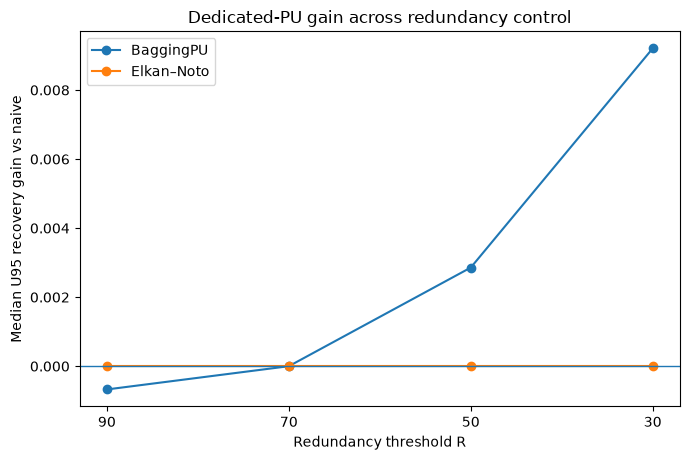

In [24]:
gain_by_R = (
    primary_gains.groupby(["method", "R"])
    ["gain_vs_naive"]
    .agg(
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_practical_tie=lambda x: (x.abs() <= 0.02).mean(),
    )
    .reset_index()
)

display(gain_by_R)

fig, ax = plt.subplots(figsize=(7.0, 4.7))

for method in DEDICATED_METHODS:
    g = (
        gain_by_R[
            gain_by_R["method"].eq(method)
        ]
        .assign(
            order=lambda x: x["R"].map(
                {90: 0, 70: 1, 50: 2, 30: 3}
            )
        )
        .sort_values("order")
    )

    ax.plot(
        g["R"].astype(str),
        g["median"],
        marker="o",
        label=METHOD_LABELS[method],
    )

ax.axhline(0, linewidth=1)
ax.set_xlabel("Redundancy threshold R")
ax.set_ylabel("Median U95 recovery gain vs naive")
ax.set_title("Dedicated-PU gain across redundancy control")
ax.legend()
plt.tight_layout()
plt.show()

# 23. Method-gain surface across S

,method,S,mean,median,q25,q75,fraction_positive,fraction_practical_tie
0,baggingpu,30,0.024358,0.002800,-0.002820,0.014024,0.609375,0.765625
1,baggingpu,50,0.024971,0.001003,-0.003252,0.013600,0.531250,0.796875
2,baggingpu,70,0.023200,0.000000,-0.006296,0.011495,0.484375,0.765625
3,baggingpu,90,0.020903,-0.000350,-0.007057,0.014670,0.484375,0.718750
4,elkan_noto,30,0.008679,0.000000,0.000000,0.000000,0.156250,0.875000
5,elkan_noto,50,0.008297,0.000000,0.000000,0.000000,0.156250,0.859375
6,elkan_noto,70,0.006024,0.000000,0.000000,0.000000,0.140625,0.875000
7,elkan_noto,90,0.005864,0.000000,0.000000,0.000000,0.140625,0.890625


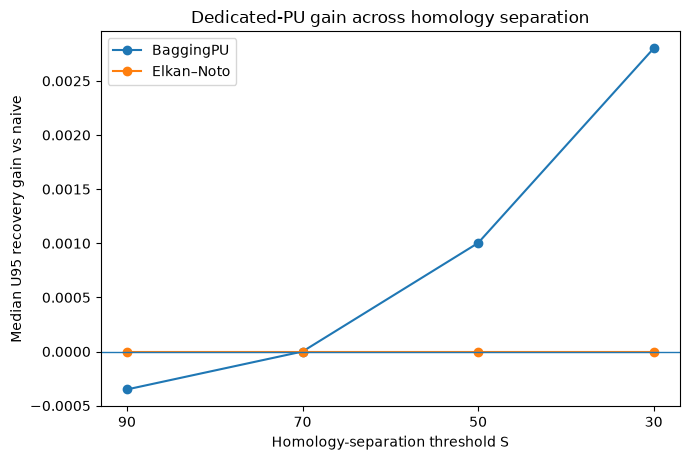

In [25]:
gain_by_S = (
    primary_gains.groupby(["method", "S"])
    ["gain_vs_naive"]
    .agg(
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_practical_tie=lambda x: (x.abs() <= 0.02).mean(),
    )
    .reset_index()
)

display(gain_by_S)

fig, ax = plt.subplots(figsize=(7.0, 4.7))

for method in DEDICATED_METHODS:
    g = (
        gain_by_S[
            gain_by_S["method"].eq(method)
        ]
        .assign(
            order=lambda x: x["S"].map(
                {90: 0, 70: 1, 50: 2, 30: 3}
            )
        )
        .sort_values("order")
    )

    ax.plot(
        g["S"].astype(str),
        g["median"],
        marker="o",
        label=METHOD_LABELS[method],
    )

ax.axhline(0, linewidth=1)
ax.set_xlabel("Homology-separation threshold S")
ax.set_ylabel("Median U95 recovery gain vs naive")
ax.set_title("Dedicated-PU gain across homology separation")
ax.legend()
plt.tight_layout()
plt.show()

# 24. Does stricter R change the benefit of dedicated PU learning?

In [26]:
gain_R_shift_rows = []

gain_surface_keys = [
    "task",
    "representation",
    "algorithm",
    "method",
]

for keys, grp in primary_gains.groupby(gain_surface_keys):
    lookup = {
        (int(r), int(s)): float(v)
        for r, s, v in zip(
            grp["R"],
            grp["S"],
            grp["gain_vs_naive"],
        )
    }

    for s in S_LEVELS:
        if (90, s) in lookup and (30, s) in lookup:
            row = dict(zip(gain_surface_keys, keys))
            row.update({
                "S_fixed": s,
                "gain_R90": lookup[(90, s)],
                "gain_R30": lookup[(30, s)],
                "delta_gain_R30_minus_R90": (
                    lookup[(30, s)] - lookup[(90, s)]
                ),
            })
            gain_R_shift_rows.append(row)

gain_R_shift = pd.DataFrame(
    gain_R_shift_rows
)

display(
    gain_R_shift.groupby("method")
    ["delta_gain_R30_minus_R90"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_negative=lambda x: (x < 0).mean(),
    )
    .reindex(DEDICATED_METHODS)
)

,n,mean,median,median_abs,fraction_positive,fraction_negative
method,,,,,,
baggingpu,64,0.019280,0.008312,0.014508,0.750000,0.234375
elkan_noto,64,-0.001336,0.000000,0.000000,0.078125,0.109375


Positive `Δgain_R` means the dedicated method's advantage over naive becomes larger at R30 than at R90.

Negative values mean the dedicated-method advantage contracts as redundancy control becomes stricter.

# 25. Does stricter S change the benefit of dedicated PU learning?

In [27]:
gain_S_shift_rows = []

for keys, grp in primary_gains.groupby(gain_surface_keys):
    lookup = {
        (int(r), int(s)): float(v)
        for r, s, v in zip(
            grp["R"],
            grp["S"],
            grp["gain_vs_naive"],
        )
    }

    for r in R_LEVELS:
        if (r, 90) in lookup and (r, 30) in lookup:
            row = dict(zip(gain_surface_keys, keys))
            row.update({
                "R_fixed": r,
                "gain_S90": lookup[(r, 90)],
                "gain_S30": lookup[(r, 30)],
                "delta_gain_S30_minus_S90": (
                    lookup[(r, 30)] - lookup[(r, 90)]
                ),
            })
            gain_S_shift_rows.append(row)

gain_S_shift = pd.DataFrame(
    gain_S_shift_rows
)

display(
    gain_S_shift.groupby("method")
    ["delta_gain_S30_minus_S90"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_negative=lambda x: (x < 0).mean(),
    )
    .reindex(DEDICATED_METHODS)
)

,n,mean,median,median_abs,fraction_positive,fraction_negative
method,,,,,,
baggingpu,64,0.003455,0.002051,0.008188,0.578125,0.421875
elkan_noto,64,0.002816,0.000000,0.000000,0.109375,0.046875


# 26. Extreme R×S interaction in PU-method gain

In [28]:
gain_interaction_rows = []

for keys, grp in primary_gains.groupby(gain_surface_keys):
    lookup = {
        (int(r), int(s)): float(v)
        for r, s, v in zip(
            grp["R"],
            grp["S"],
            grp["gain_vs_naive"],
        )
    }

    required = [
        (90, 90),
        (30, 90),
        (90, 30),
        (30, 30),
    ]

    if not all(cell in lookup for cell in required):
        continue

    g00 = lookup[(90, 90)]
    g10 = lookup[(30, 90)]
    g01 = lookup[(90, 30)]
    g11 = lookup[(30, 30)]

    interaction = (
        (g11 - g01)
        - (g10 - g00)
    )

    row = dict(zip(gain_surface_keys, keys))
    row.update({
        "gain_R90_S90": g00,
        "gain_R30_S90": g10,
        "gain_R90_S30": g01,
        "gain_R30_S30": g11,
        "interaction": interaction,
    })

    gain_interaction_rows.append(row)

gain_interactions = pd.DataFrame(
    gain_interaction_rows
)

display(
    gain_interactions.groupby("method")
    ["interaction"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
    )
    .reindex(DEDICATED_METHODS)
)

,n,mean,median,median_abs
method,,,,
baggingpu,16,-0.011826,-0.006307,0.014131
elkan_noto,16,-0.010686,0.000000,0.000000


# 27. Dedicated-method gains across supporting metrics

In [29]:
gain_metric_summary = (
    method_gains.groupby(["metric", "method"])
    ["gain_vs_naive"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_practical_tie=lambda x: (
            x.abs()
            <= PRACTICAL_TIE.get(x.name[0] if isinstance(x.name, tuple) else "", 0.02)
        ).mean(),
    )
    .reset_index()
)

# Recompute practical-tie fraction robustly because groupby Series.name
# can vary across pandas versions.
tie_rows = []
for (metric, method), grp in method_gains.groupby(["metric", "method"]):
    d = grp["gain_vs_naive"]
    threshold = PRACTICAL_TIE.get(metric, 0.02)
    tie_rows.append({
        "metric": metric,
        "method": method,
        "practical_tie_threshold": threshold,
        "fraction_practical_tie": (d.abs() <= threshold).mean(),
    })

gain_ties = pd.DataFrame(tie_rows)

gain_metric_summary = (
    gain_metric_summary.drop(columns=["fraction_practical_tie"])
    .merge(
        gain_ties,
        on=["metric", "method"],
        how="left",
        validate="one_to_one",
    )
)

display(gain_metric_summary)

,metric,method,n,mean,median,median_abs,fraction_positive,practical_tie_threshold,fraction_practical_tie
0,fraction_P_above_U90,baggingpu,256,0.032540,0.002080,0.006198,0.589844,0.02,0.808594
1,fraction_P_above_U90,elkan_noto,256,0.000000,0.000000,0.000000,0.000000,0.02,1.000000
2,fraction_P_above_U95,baggingpu,256,0.023358,0.001180,0.007299,0.527344,0.02,0.761719
3,fraction_P_above_U95,elkan_noto,256,0.007216,0.000000,0.000000,0.148438,0.02,0.875000
4,fraction_P_above_U99,baggingpu,256,-0.001810,-0.002363,0.016892,0.449219,0.02,0.558594
5,fraction_P_above_U99,elkan_noto,256,0.134217,0.101196,0.101196,0.710938,0.02,0.324219
6,fraction_P_strictly_above_U99,baggingpu,256,-0.001810,-0.002363,0.016892,0.449219,0.02,0.558594
7,fraction_P_strictly_above_U99,elkan_noto,256,-0.303851,-0.254012,0.254012,0.000000,0.02,0.289062
8,median_P_percentile_vs_U,baggingpu,256,0.013415,0.000091,0.000703,0.539062,0.02,0.878906
9,median_P_percentile_vs_U,elkan_noto,256,0.010123,0.003581,0.003581,0.867188,0.02,0.804688


A method gain that appears only for canonical U99 but disappears for **strict U99** is not evidence of stronger resolved ranking; it may reflect quantile-boundary ties.

# 28. Elkan–Noto U99 ceiling behavior across R/S

In [30]:
en_tie_cols = [
    c for c in [
        "U_q99",
        "U_tie_fraction_at_q99",
        "U_fraction_at_score_1",
        "P_fraction_at_score_1",
        "P_recovery_tie_component_U99",
    ]
    if c in native.columns
]

if en_tie_cols:
    en_rs_ties = (
        native[
            native["method"].eq("elkan_noto")
        ]
        .groupby(["R", "S"])
        .agg(
            **{
                f"{c}_median": (c, "median")
                for c in en_tie_cols
            }
        )
        .reset_index()
    )

    display(en_rs_ties)
else:
    en_rs_ties = pd.DataFrame()

print(
    "Canonical U99 should not be interpreted without this tie context."
)

,R,S,U_q99_median,U_tie_fraction_at_q99_median,U_fraction_at_score_1_median,P_fraction_at_score_1_median,P_recovery_tie_component_U99_median
0,30,30,1.0,0.026696,0.026696,0.619831,0.531066
1,30,50,1.0,0.024127,0.024127,0.627206,0.571230
2,30,70,1.0,0.025647,0.025647,0.640588,0.571846
3,30,90,1.0,0.025986,0.025986,0.615284,0.524063
4,50,30,1.0,0.024671,0.024671,0.640252,0.585756
5,50,50,1.0,0.022174,0.022174,0.645044,0.577426
6,50,70,1.0,0.023578,0.023578,0.651325,0.587169
7,50,90,1.0,0.022036,0.022036,0.649335,0.560149
8,70,30,1.0,0.020890,0.020890,0.665276,0.569799
9,70,50,1.0,0.021389,0.021389,0.685567,0.562637


Canonical U99 should not be interpreted without this tie context.


# 29. Does R/S alter positive test support enough to contextualize native-test curves?

In [31]:
support_context = (
    native.groupby(["task", "R", "S"])
    .agg(
        n_P_test=("n_P_test", "first"),
        n_U_test=("n_U_test", "first"),
    )
    .reset_index()
)

display(
    support_context.groupby(["task", "R"])
    .agg(
        median_P_test=("n_P_test", "median"),
        min_P_test=("n_P_test", "min"),
        max_P_test=("n_P_test", "max"),
        median_U_test=("n_U_test", "median"),
    )
    .reset_index()
)

display(
    support_context.groupby(["task", "S"])
    .agg(
        median_P_test=("n_P_test", "median"),
        min_P_test=("n_P_test", "min"),
        max_P_test=("n_P_test", "max"),
        median_U_test=("n_U_test", "median"),
    )
    .reset_index()
)

,task,R,median_P_test,min_P_test,max_P_test,median_U_test
0,pu_broad,30,489.0,482,491,34378.5
1,pu_broad,50,707.0,688,734,41897.5
2,pu_broad,70,1079.0,1073,1096,50841.0
3,pu_broad,90,1461.0,1428,1519,64342.5
4,pu_conservative,30,476.0,472,484,26119.0
5,pu_conservative,50,715.0,704,720,30276.5
6,pu_conservative,70,1003.0,959,1043,35704.0
7,pu_conservative,90,1437.0,1420,1472,44134.5


,task,S,median_P_test,min_P_test,max_P_test,median_U_test
0,pu_broad,30,892.0,491,1485,46317.0
1,pu_broad,50,903.5,487,1519,46350.0
2,pu_broad,70,896.5,482,1437,46370.0
3,pu_broad,90,889.5,491,1428,46402.5
4,pu_conservative,30,836.0,472,1472,33001.5
5,pu_conservative,50,845.0,474,1452,33010.5
6,pu_conservative,70,876.5,478,1422,32973.5
7,pu_conservative,90,873.5,484,1420,32970.0


These counts are contextual only.

Variation in native test support/composition is one reason R/S contrasts are not interpreted as entity-paired causal effects. The common-test analysis in RQ16 is reserved for separating model behavior from changing test composition.

# 30. Descriptive support–recovery association

In [32]:
support_recovery = (
    cell_summary.groupby(
        ["task", "R", "S"]
    )
    .agg(
        n_P_test=("n_P_test", "first"),
        n_U_test=("n_U_test", "first"),
        recovery_median_across_methods=("U95_median", "median"),
    )
    .reset_index()
)

support_assoc_rows = []

for task in TASKS:
    g = support_recovery[
        support_recovery["task"].eq(task)
    ]

    support_assoc_rows.append({
        "task": task,
        "n_cells": len(g),
        "rho_nP_vs_recovery": (
            g["n_P_test"].corr(
                g["recovery_median_across_methods"],
                method="spearman",
            )
        ),
        "rho_nU_vs_recovery": (
            g["n_U_test"].corr(
                g["recovery_median_across_methods"],
                method="spearman",
            )
        ),
    })

support_associations = pd.DataFrame(
    support_assoc_rows
)

display(support_associations)

,task,n_cells,rho_nP_vs_recovery,rho_nU_vs_recovery
0,pu_conservative,16,0.926471,0.929412
1,pu_broad,16,0.896247,0.932353


These correlations are descriptive only. `R` and `S` simultaneously change support, sequence composition, homology topology, and the fitted models.

# 31. Compact RQ13 regime summary

In [33]:
summary_rows = []

for method in METHODS:
    r = primary_R[
        primary_R["method"].eq(method)
    ]["delta_R30_minus_R90"]

    s = primary_S[
        primary_S["method"].eq(method)
    ]["delta_S30_minus_S90"]

    d = dominance[
        dominance["method"].eq(method)
    ]["dominance_index"]

    i = interactions[
        interactions["method"].eq(method)
    ]["interaction"]

    summary_rows.append({
        "method": method,
        "R30_minus_R90_median": r.median(),
        "R_abs_median": r.abs().median(),
        "R_fraction_negative": (r < 0).mean(),
        "S30_minus_S90_median": s.median(),
        "S_abs_median": s.abs().median(),
        "S_fraction_negative": (s < 0).mean(),
        "dominance_index_median": d.median(),
        "extreme_RxS_interaction_median": i.median(),
        "extreme_RxS_interaction_abs_median": i.abs().median(),
    })

rq13_regime_summary = pd.DataFrame(
    summary_rows
)

display(rq13_regime_summary)

,method,R30_minus_R90_median,R_abs_median,R_fraction_negative,S30_minus_S90_median,S_abs_median,S_fraction_negative,dominance_index_median,extreme_RxS_interaction_median,extreme_RxS_interaction_abs_median
0,naive,-0.082699,0.082699,0.984375,-0.008214,0.014574,0.734375,0.637669,0.029822,0.029822
1,baggingpu,-0.066403,0.066403,0.921875,-0.007135,0.011587,0.703125,0.621464,0.025671,0.025671
2,elkan_noto,-0.082699,0.082699,0.984375,-0.007298,0.012576,0.734375,0.672860,0.027231,0.027231


# 32. Compact dedicated-PU gain summary

In [34]:
gain_summary_rows = []

for method in DEDICATED_METHODS:
    g = primary_gains[
        primary_gains["method"].eq(method)
    ]["gain_vs_naive"]

    gr = gain_R_shift[
        gain_R_shift["method"].eq(method)
    ]["delta_gain_R30_minus_R90"]

    gs = gain_S_shift[
        gain_S_shift["method"].eq(method)
    ]["delta_gain_S30_minus_S90"]

    gi = gain_interactions[
        gain_interactions["method"].eq(method)
    ]["interaction"]

    gain_summary_rows.append({
        "method": method,
        "U95_gain_vs_naive_median": g.median(),
        "U95_gain_vs_naive_abs_median": g.abs().median(),
        "U95_gain_positive_fraction": (g > 0).mean(),
        "U95_gain_practical_tie_fraction": (g.abs() <= 0.02).mean(),
        "gain_change_R30_minus_R90_median": gr.median(),
        "gain_change_S30_minus_S90_median": gs.median(),
        "gain_RxS_interaction_median": gi.median(),
        "gain_RxS_interaction_abs_median": gi.abs().median(),
    })

rq13_gain_summary = pd.DataFrame(
    gain_summary_rows
)

display(rq13_gain_summary)

,method,U95_gain_vs_naive_median,U95_gain_vs_naive_abs_median,U95_gain_positive_fraction,U95_gain_practical_tie_fraction,gain_change_R30_minus_R90_median,gain_change_S30_minus_S90_median,gain_RxS_interaction_median,gain_RxS_interaction_abs_median
0,baggingpu,0.00118,0.007299,0.527344,0.761719,0.008312,0.002051,-0.006307,0.014131
1,elkan_noto,0.00000,0.000000,0.148438,0.875000,0.000000,0.000000,0.000000,0.000000


# 33. RQ13 synthesis questions

After execution, RQ13 should answer:

1. Does stricter redundancy reduction systematically reduce PU positive recovery?
2. Does stricter homology separation systematically reduce recovery?
3. Is the R effect larger than the S effect, or vice versa?
4. Are the effects monotonic or strongly nonmonotonic?
5. Is there a universal R or S breakpoint?
6. How much R×S non-additivity exists in PU recovery?
7. Are naive, BaggingPU, and Elkan–Noto similarly sensitive to R/S?
8. Does BaggingPU's gain over naive increase under stricter R?
9. Does BaggingPU's gain over naive increase under stricter S?
10. Does Elkan–Noto's gain over naive increase under stricter R/S?
11. Are apparent method gains dominated by practical ties?
12. Do U90/U95/positive-percentile diagnostics support the same R/S story?
13. Does strict U99 contradict canonical U99 because of Elkan–Noto ceiling ties?
14. Does changing native positive-test support plausibly contribute to observed R/S volatility?
15. Does stricter generalization make the **choice of PU paradigm** more consequential, or does the method gap remain approximately constant?

The desired conclusion is not:

> “R30 or S30 is the best/worst threshold.”

The useful conclusion is whether PU generalization degrades smoothly, remains robust, or changes in a regime-dependent way—and whether explicit PU learning becomes more valuable when local sequence similarity is progressively removed.

## Manuscript-level conceptual target

If supported:

> **Positive–unlabeled learning occupies its own generalization landscape. Redundancy reduction and homology separation can alter the recovery of labeled positives even though the unlabeled class is never interpreted as a confirmed negative population. Critically, the value of a dedicated PU strategy must be evaluated across this landscape: a method that is nearly indistinguishable from naive P-vs-U under permissive sequence conditions may become more—or less—consequential as sequence redundancy and local homology are removed.**

Broader methodological point:

> **The consequences of label uncertainty and the consequences of sequence similarity control are not independent assumptions; their interaction determines how reliably known positives can be recovered from an incompletely annotated protein universe.**

# 34. Export RQ13 cache tables

In [35]:
CELL_PATH = CACHE_DIR / "rq13_pu_rs_cell_summary.tsv"
R_EFFECT_PATH = CACHE_DIR / "rq13_pu_R_extreme_effects.tsv"
S_EFFECT_PATH = CACHE_DIR / "rq13_pu_S_extreme_effects.tsv"
R_STEP_PATH = CACHE_DIR / "rq13_pu_R_stepwise_effects.tsv"
S_STEP_PATH = CACHE_DIR / "rq13_pu_S_stepwise_effects.tsv"
R_SHAPE_PATH = CACHE_DIR / "rq13_pu_R_curve_shapes.tsv"
S_SHAPE_PATH = CACHE_DIR / "rq13_pu_S_curve_shapes.tsv"
INTERACTION_PATH = CACHE_DIR / "rq13_pu_extreme_RxS_interactions.tsv"
DOMINANCE_PATH = CACHE_DIR / "rq13_pu_R_vs_S_dominance.tsv"
GAINS_PATH = CACHE_DIR / "rq13_pu_method_gains_vs_naive.tsv"
GAIN_R_PATH = CACHE_DIR / "rq13_pu_gain_R_shift.tsv"
GAIN_S_PATH = CACHE_DIR / "rq13_pu_gain_S_shift.tsv"
GAIN_INTERACTION_PATH = CACHE_DIR / "rq13_pu_gain_RxS_interaction.tsv"
GAIN_METRIC_PATH = CACHE_DIR / "rq13_pu_gain_metric_summary.tsv"
EN_TIE_PATH = CACHE_DIR / "rq13_elkan_noto_U99_tie_context.tsv"
SUPPORT_PATH = CACHE_DIR / "rq13_pu_test_support_context.tsv"
SUPPORT_ASSOC_PATH = CACHE_DIR / "rq13_pu_support_recovery_associations.tsv"
REGIME_PATH = CACHE_DIR / "rq13_pu_regime_summary.tsv"
GAIN_SUMMARY_PATH = CACHE_DIR / "rq13_pu_gain_summary.tsv"

cell_summary.to_csv(
    CELL_PATH,
    sep="\t",
    index=False,
)
R_effects.to_csv(
    R_EFFECT_PATH,
    sep="\t",
    index=False,
)
S_effects.to_csv(
    S_EFFECT_PATH,
    sep="\t",
    index=False,
)
step_R.to_csv(
    R_STEP_PATH,
    sep="\t",
    index=False,
)
step_S.to_csv(
    S_STEP_PATH,
    sep="\t",
    index=False,
)
R_shapes.to_csv(
    R_SHAPE_PATH,
    sep="\t",
    index=False,
)
S_shapes.to_csv(
    S_SHAPE_PATH,
    sep="\t",
    index=False,
)
interactions.to_csv(
    INTERACTION_PATH,
    sep="\t",
    index=False,
)
dominance.to_csv(
    DOMINANCE_PATH,
    sep="\t",
    index=False,
)
method_gains.to_csv(
    GAINS_PATH,
    sep="\t",
    index=False,
)
gain_R_shift.to_csv(
    GAIN_R_PATH,
    sep="\t",
    index=False,
)
gain_S_shift.to_csv(
    GAIN_S_PATH,
    sep="\t",
    index=False,
)
gain_interactions.to_csv(
    GAIN_INTERACTION_PATH,
    sep="\t",
    index=False,
)
gain_metric_summary.to_csv(
    GAIN_METRIC_PATH,
    sep="\t",
    index=False,
)
en_rs_ties.to_csv(
    EN_TIE_PATH,
    sep="\t",
    index=False,
)
support_context.to_csv(
    SUPPORT_PATH,
    sep="\t",
    index=False,
)
support_associations.to_csv(
    SUPPORT_ASSOC_PATH,
    sep="\t",
    index=False,
)
rq13_regime_summary.to_csv(
    REGIME_PATH,
    sep="\t",
    index=False,
)
rq13_gain_summary.to_csv(
    GAIN_SUMMARY_PATH,
    sep="\t",
    index=False,
)

print("Saved:")
for p in [
    CELL_PATH,
    R_EFFECT_PATH,
    S_EFFECT_PATH,
    R_STEP_PATH,
    S_STEP_PATH,
    R_SHAPE_PATH,
    S_SHAPE_PATH,
    INTERACTION_PATH,
    DOMINANCE_PATH,
    GAINS_PATH,
    GAIN_R_PATH,
    GAIN_S_PATH,
    GAIN_INTERACTION_PATH,
    GAIN_METRIC_PATH,
    EN_TIE_PATH,
    SUPPORT_PATH,
    SUPPORT_ASSOC_PATH,
    REGIME_PATH,
    GAIN_SUMMARY_PATH,
]:
    print(" ", p)

Saved:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq13_pu_rs_cell_summary.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq13_pu_R_extreme_effects.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq13_pu_S_extreme_effects.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq13_pu_R_stepwise_effects.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq13_pu_S_stepwise_effects.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq13_pu_R_curve_shapes.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq13_pu_S_c

## Final interpretation guardrails

- U is unlabeled, never a confirmed negative population.
- U95 recovery is the primary RQ13 metric.
- Canonical U99 must always be interpreted with strict U99 and tie/ceiling diagnostics.
- Method-vs-naive gains are paired only **within the same R/S cell**.
- Native R/S deltas are not entity-level paired across thresholds.
- Do not call a positive or negative R/S delta causal.
- Do not interpret R or S thresholds as linear distances.
- Do not infer the conservative-vs-broad U-universe effect here; that belongs to RQ14.
- Do not infer representation × PU-method interaction here; that belongs to RQ15.
- Do not interpret test-support correlations causally.
- No threshold is selected retrospectively from outer-test behavior.